<a href="https://colab.research.google.com/github/hwollwage/PCVK_2026/blob/main/week_07_15_244107020157.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


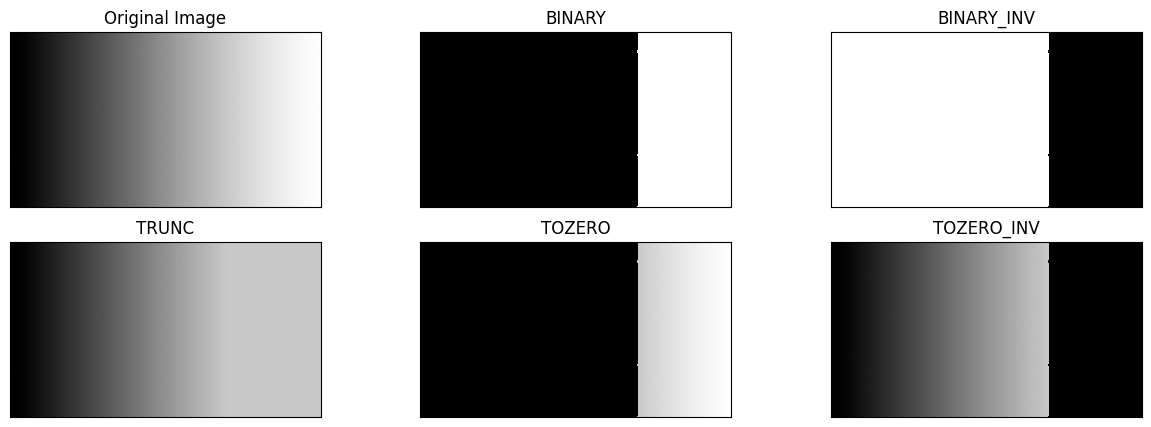

In [4]:
filename = ('/content/drive/MyDrive/Colab Notebooks/gambar/gradient.jpg')
img = cv.imread(filename)
thresh = 200
maxval=255
ret,thresh1 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY)
ret,thresh2 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY_INV)
ret,thresh3 = cv.threshold(img,thresh,maxval,cv.THRESH_TRUNC)
ret,thresh4 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO)
ret,thresh5 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO_INV)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]
plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

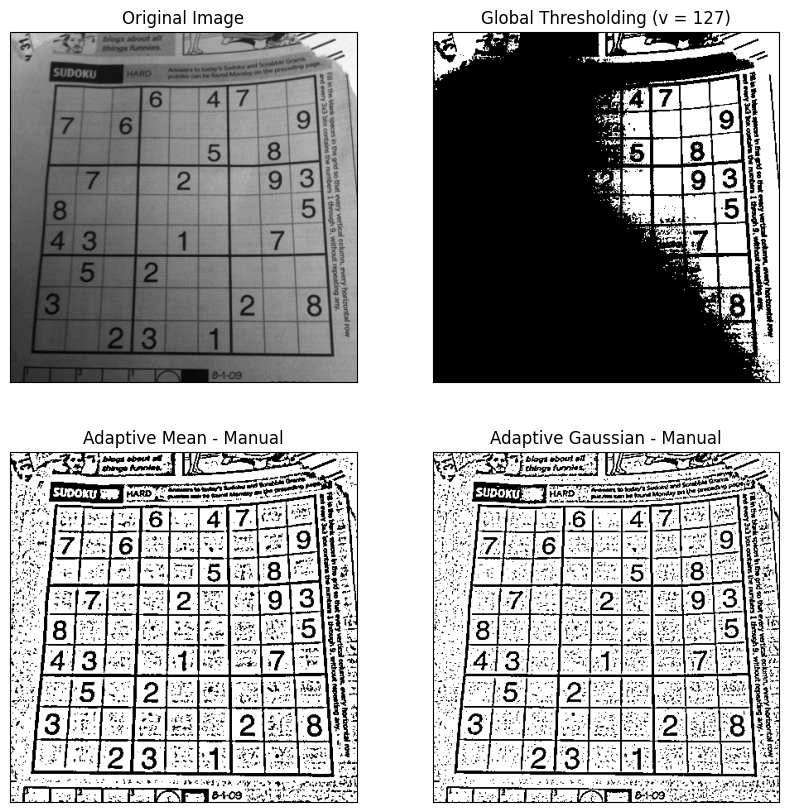

In [5]:
filename = ('/content/drive/MyDrive/Colab Notebooks/gambar/sudoku-original.jpg')

citra = cv.imread(filename)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

def create_gaussian_kernel(size=11, sigma=2.0):
  k = size // 2
  x, y = np.mgrid[-k : k + 1, -k : k + 1]
  # Gaussian 2D: exp(-(x^2 + y^2) / (2 * sigma^2))
  kernel = np.exp(-(x**2 + y**2) / (2.0 * sigma**2))
  return kernel / np.sum(kernel)

def adaptive_mean_manual(img, window_size=11, C=2):
  pad = window_size // 2
  padded = np.pad(img, pad, mode='reflect')
  windows = np.lib.stride_tricks.sliding_window_view(
      padded, (window_size, window_size)
  )

  local_mean = windows.mean(axis=(2, 3))

  thresh_local = local_mean - C

  return np.where(img > thresh_local, 255, 0).astype(np.uint8)

def adaptive_gaussian_manual(img, window_size=11, C=2, sigma=2.0):
  pad = window_size // 2
  padded = np.pad(img, pad, mode='reflect')

  kernel = create_gaussian_kernel(window_size, sigma)

  windows = np.lib.stride_tricks.sliding_window_view(
      padded, (window_size, window_size)
  )

  local_gaussian = np.sum(windows * kernel, axis=(2, 3))

  thresh_local = local_gaussian - C

  return np.where(img > thresh_local, 255, 0).astype(np.uint8)

thresh = 127
th1 = np.where(gray > thresh, 255, 0).astype(np.uint8)

th2 = adaptive_mean_manual(gray, window_size=11, C=2)

th3 = adaptive_gaussian_manual(gray, window_size=11, C=2, sigma=2.0)

titles = [
    'Original Image',
    'Global Thresholding (v = 127)',
    'Adaptive Mean - Manual',
    'Adaptive Gaussian - Manual',
]

citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(10, 10))
for i in range(len(citra2)):
  plt.subplot(2, 2, i + 1)
  plt.imshow(citra2[i], 'gray')
  plt.title(titles[i])
  plt.xticks([])
  plt.yticks([])
plt.show()

93


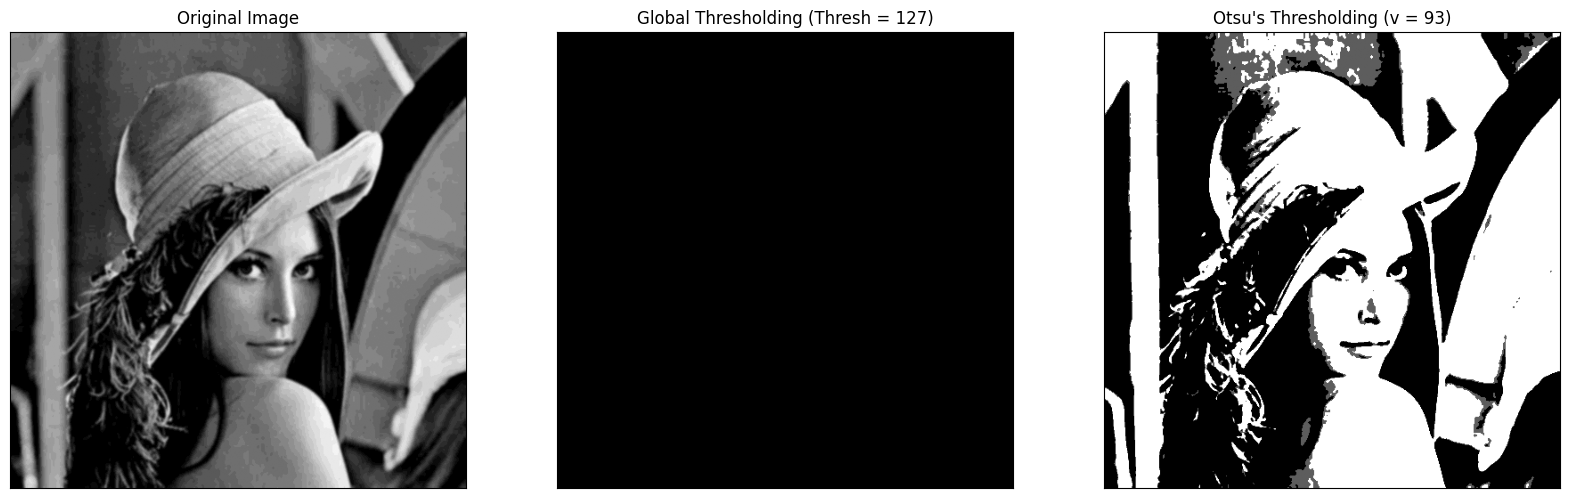

In [6]:
filename = ('/content/drive/MyDrive/Colab Notebooks/gambar/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    if pcb == 0 or pcf == 0:
      continue

    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2

    if value > final_value:
      final_thresh = t
      final_value = value

  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Original Image', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

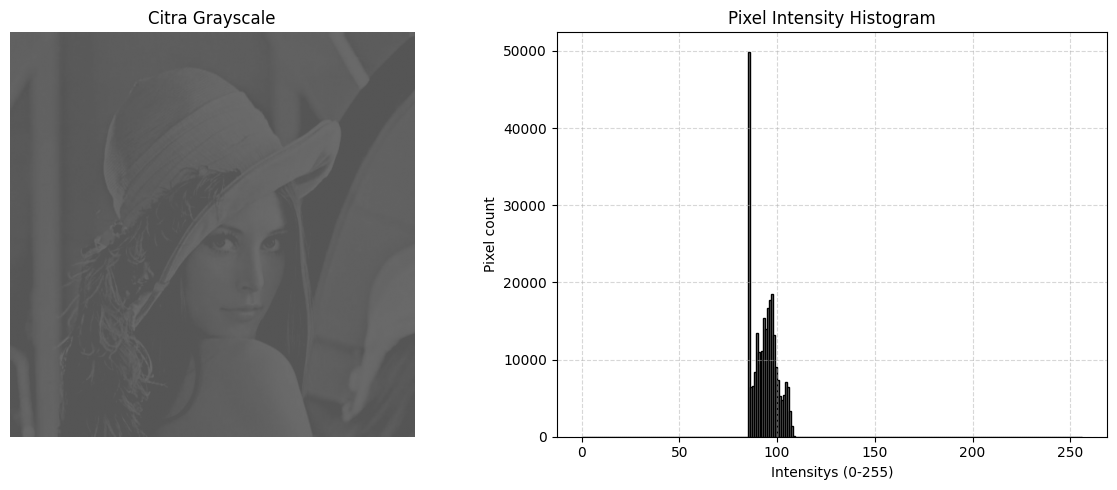

In [7]:
filename = '/content/drive/MyDrive/Colab Notebooks/gambar/lena_gs_lc2.jpg'
img = cv.imread(filename, 0)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Citra Grayscale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray', edgecolor='black')
plt.title('Pixel Intensity Histogram')
plt.xlabel('Intensitys (0-255)')
plt.ylabel('Pixel count')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

166


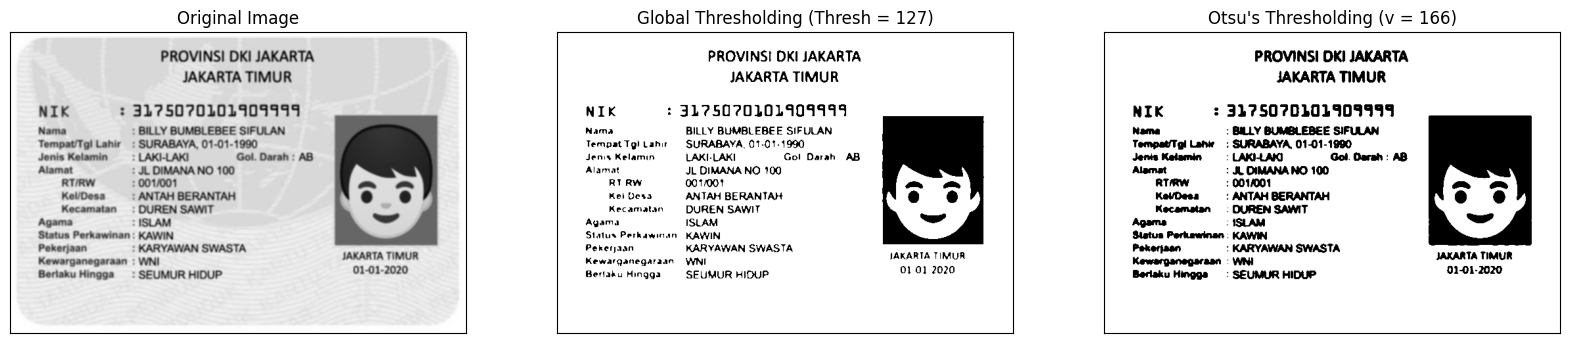

In [8]:
filename = ('/content/drive/MyDrive/Colab Notebooks/gambar/ktp1.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    if pcb == 0 or pcf == 0:
      continue

    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2

    if value > final_value:
      final_thresh = t
      final_value = value

  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Original Image', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

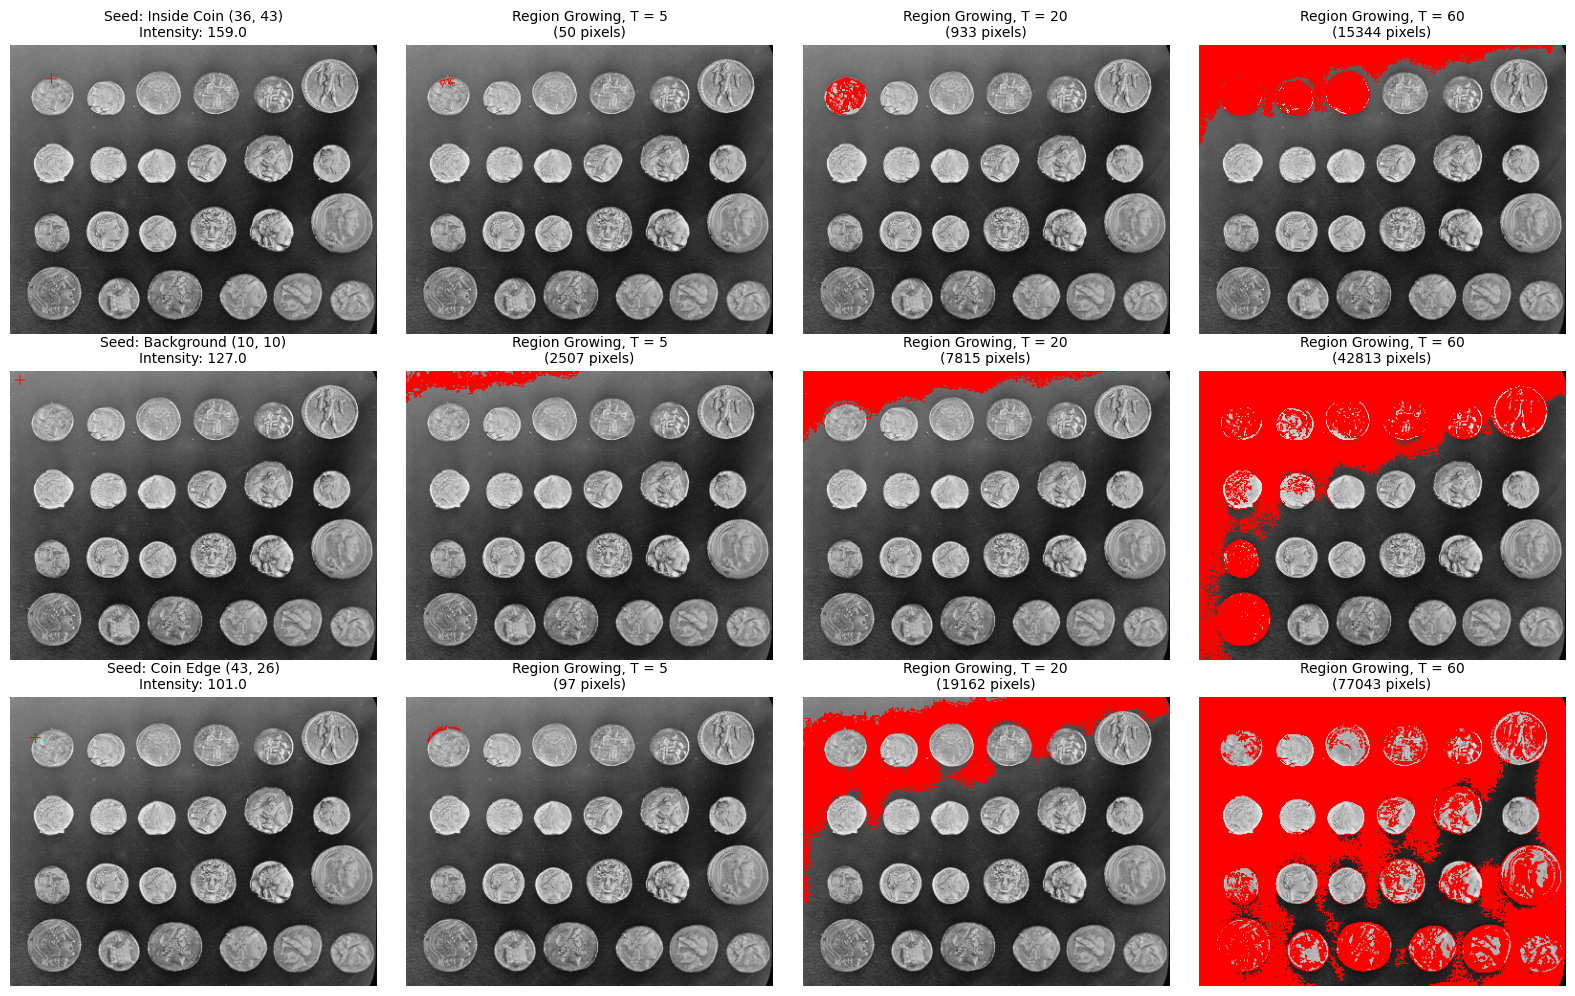

In [9]:
from skimage import data
from skimage.segmentation import flood
img = data.coins()

def region_growing(img, seed, T):
  H, W = img.shape
  mask = np.zeros((H, W), dtype=bool)
  visited = np.zeros((H, W), dtype=bool)

  sr, sc = seed
  seed_val = float(img[sr, sc])

  queue = deque([(sr, sc)])
  visited[sr, sc] = True
  mask[sr, sc] = True

  neighbors = [
      (-1, -1),
      (-1, 0),
      (-1, 1),
      (0, -1),
      (0, 1),
      (1, -1),
      (1, 0),
      (1, 1),
  ]

  while queue:
    r, c = queue.popleft()

    for dr, dc in neighbors:
      nr, nc = r + dr, c + dc
      if 0 <= nr < H and 0 <= nc < W and not visited[nr, nc]:
        visited[nr, nc] = True
        if abs(float(img[nr, nc]) - seed_val) <= T:
          mask[nr, nc] = True
          queue.append((nr, nc))

  return mask


def mark_seed_on_image(img, seed, cross_size=5):
  rgb = np.stack([img] * 3, axis=-1)
  r, c = seed
  r_min, r_max = max(0, r - cross_size), min(img.shape[0], r + cross_size + 1)
  c_min, c_max = max(0, c - cross_size), min(img.shape[1], c + cross_size + 1)

  rgb[r_min:r_max, c] = [255, 0, 0]
  rgb[r, c_min:c_max] = [255, 0, 0]
  return rgb


def overlay_mask(img, mask):
  rgb = np.stack([img] * 3, axis=-1)
  rgb[mask] = [255, 0, 0]
  return rgb

seeds = [
    (36, 43),
    (10, 10),
    (43, 26),
]

seed_labels = [
    'Inside Coin (36, 43)',
    'Background (10, 10)',
    'Coin Edge (43, 26)',
]

thresholds = [5, 20, 60]

fig, axes = plt.subplots(
    nrows=len(seeds), ncols=len(thresholds) + 1, figsize=(16, 10)
)

for i, (seed, label) in enumerate(zip(seeds, seed_labels)):
  seed_val = img[seed[0], seed[1]]

  img_with_seed = mark_seed_on_image(img, seed)
  axes[i, 0].imshow(img_with_seed)
  axes[i, 0].set_title(
      f'Seed: {label}\nIntensity: {seed_val:.1f}', fontsize=10
  )
  axes[i, 0].axis('off')

  for j, T in enumerate(thresholds):
    mask = region_growing(img, seed, T)
    pixel_count = np.sum(mask)
    result_img = overlay_mask(img, mask)

    axes[i, j + 1].imshow(result_img)
    axes[i, j + 1].set_title(
        f'Region Growing, T = {T}\n({pixel_count} pixels)', fontsize=10
    )
    axes[i, j + 1].axis('off')

plt.tight_layout()
plt.show()


*** Seed (row, column): (36, 43) | intensity: 159.000000
Tolerance 5: 21 pixe
Tolerance 20: 919 pixe
Tolerance 60: 15253 pixe


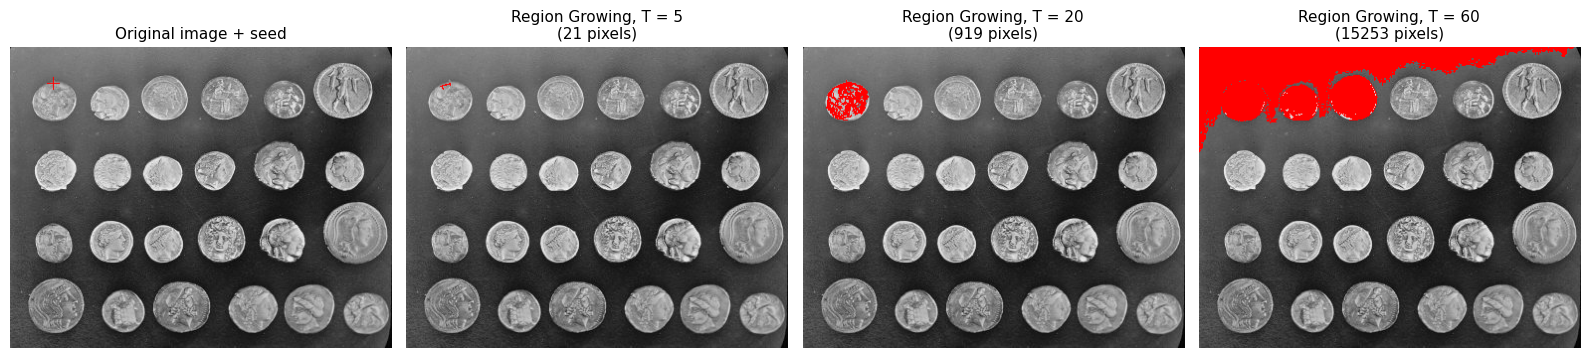

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data
from skimage.segmentation import flood

gray = data.coins()

seed = (36, 43)
seed_intensity = gray[seed[0], seed[1]]
tolerances = [5, 20, 60]

def draw_seed_marker(img, seed_pt):
  rgb = np.stack([img] * 3, axis=-1)
  r, c = seed_pt
  rgb[max(0, r - 6) : min(img.shape[0], r + 7), c] = [255, 0, 0]
  rgb[r, max(0, c - 6) : min(img.shape[1], c + 7)] = [255, 0, 0]
  return rgb

print(f'*** Seed (row, column): {seed} | intensity: {seed_intensity:.6f}')
for T in tolerances:
  m = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
  print(f'Tolerance {T}: {np.sum(m)} pixe')

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(draw_seed_marker(gray, seed))
axes[0].set_title('Original image + seed', fontsize=11)
axes[0].axis('off')

for idx, T in enumerate(tolerances):
  mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
  pixel_count = np.sum(mask)

  result_rgb = np.stack([gray] * 3, axis=-1)
  result_rgb[mask] = [255, 0, 0]

  axes[idx + 1].imshow(result_rgb)
  axes[idx + 1].set_title(
      f'Region Growing, T = {T}\n({pixel_count} pixels)', fontsize=11
  )
  axes[idx + 1].axis('off')

plt.tight_layout()
plt.show()

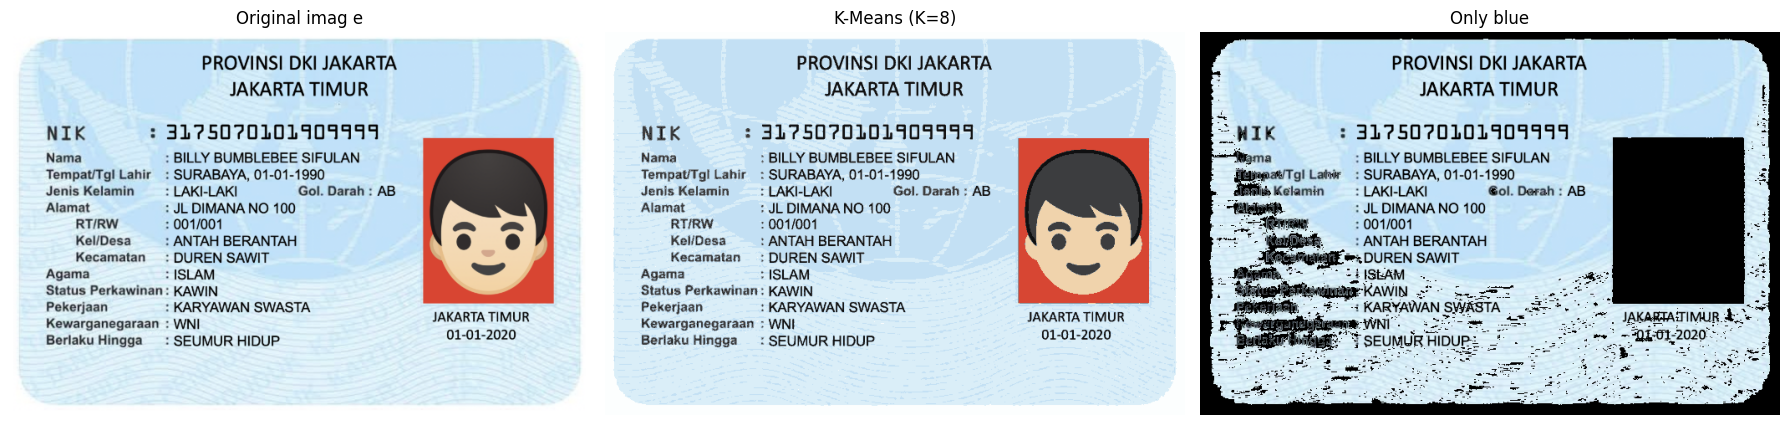

In [11]:
from sklearn.cluster import KMeans

filename = '/content/drive/MyDrive/Colab Notebooks/gambar/ktp1.jpg'
img_bgr = cv.imread(filename)

img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_hsv = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)

h, w, c = img_rgb.shape
pixels = img_rgb.reshape((-1, 3))
pixels_float = np.float32(pixels)

k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = kmeans.fit_predict(pixels_float)
centers = np.uint8(kmeans.cluster_centers_)

segmented_pixels = centers[labels]
segmented_img = segmented_pixels.reshape((h, w, c))

H = img_hsv[:, :, 0]
S = img_hsv[:, :, 1]
V = img_hsv[:, :, 2]

kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

only_blue_img = np.zeros_like(img_rgb)
only_blue_img[kelompok_biru] = img_rgb[kelompok_biru]

titles = ['Original imag e', f'K-Means (K={k})', 'Only blue']
images = [img_rgb, segmented_img, only_blue_img]

plt.figure(figsize=(18, 6))
for i in range(len(images)):
  plt.subplot(1, 3, i + 1)
  plt.imshow(images[i])
  plt.title(titles[i], fontsize=12)
  plt.axis('off')

plt.tight_layout()
plt.show()

In [15]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


=== Memproses KTM: /content/drive/MyDrive/Colab Notebooks/gambar/ktm_hanzel.jpg ===


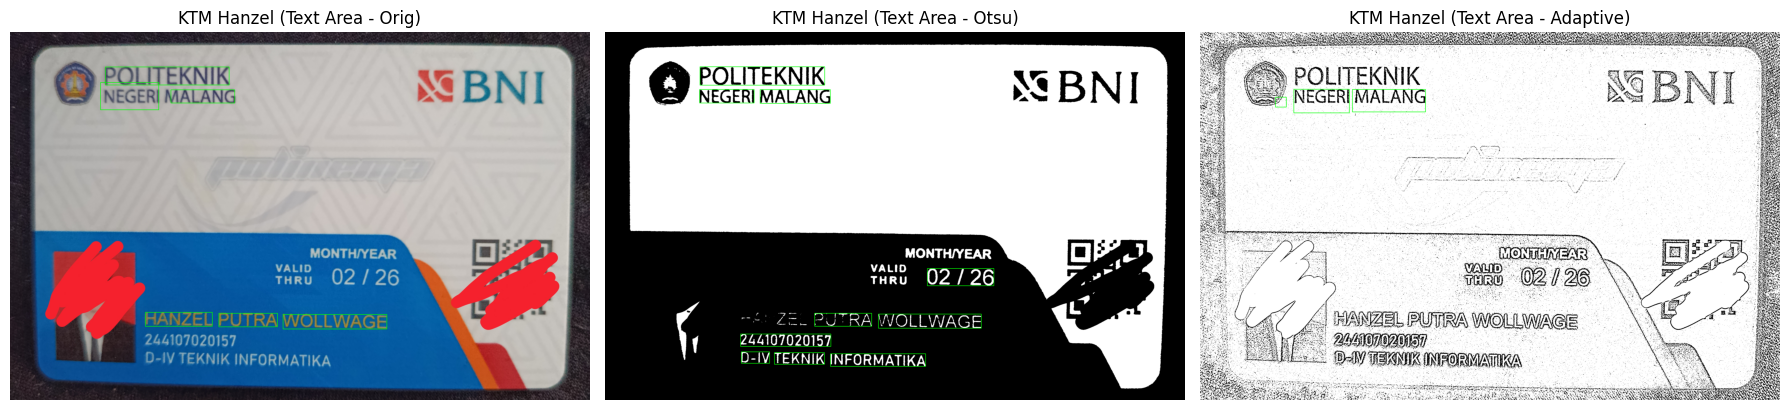


--- OCR text result ---
[Original]:
€3 POLITEKNIK
NE NEGERI MALANG

HANZEL PUTRA WOLLWAGE
----------------------------------------
[Otsu]:
A3 POLITEKNIK
ed NEGERI MALANG

tuRu 02/26

Ss LI. PUTRA WOLLWAGE
244107020157
D-IV TEKNIK INFORMATIKA
----------------------------------------
[Adaptive]:
MPOLITEKNIK
/ NEGERI MALANG

:)
----------------------------------------


In [18]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytesseract
from pytesseract import Output

filename = '/content/drive/MyDrive/Colab Notebooks/gambar/ktm_hanzel.jpg'

def process_and_ocr(image_path, lang='ind', psm=3, conf_thresh=60):
    img_bgr = cv.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f'File tidak ditemukan: {image_path}')

    img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
    gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

    # Ori
    img_color = img_rgb.copy()

    # Otsu
    _, th_otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    img_otsu_rgb = cv.cvtColor(th_otsu, cv.COLOR_GRAY2RGB)

    # Adaptive
    th_adaptive = cv.adaptiveThreshold(
        gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2
    )
    img_adaptive_rgb = cv.cvtColor(th_adaptive, cv.COLOR_GRAY2RGB)

    variants = {
        'Original': (img_color, img_rgb),
        'Otsu': (img_otsu_rgb, th_otsu),
        'Adaptive': (img_adaptive_rgb, th_adaptive),
    }

    custom_config = f'--psm {psm}'
    results_text = {}
    bounding_imgs = {}

    for name, (img_disp, img_proc) in variants.items():
        text = pytesseract.image_to_string(
            img_proc, lang=lang, config=custom_config
        )
        results_text[name] = text

        data = pytesseract.image_to_data(
            img_proc, lang=lang, config=custom_config, output_type=Output.DICT
        )
        img_box = img_disp.copy()
        n_boxes = len(data['text'])

        for i in range(n_boxes):
            try:
                conf = float(data['conf'][i])
            except (ValueError, TypeError):
                conf = -1

            if conf > conf_thresh and data['text'][i].strip() != '':
                x, y, w, h = (
                    data['left'][i],
                    data['top'][i],
                    data['width'][i],
                    data['height'][i],
                )
                cv.rectangle(img_box, (x, y), (x + w, y + h), (0, 255, 0), 2)
        bounding_imgs[name] = img_box

    return variants, results_text, bounding_imgs

def evaluate_ocr(true_texts, ocr_color, ocr_otsu, ocr_adaptive):
    rows = []
    correct_counts = {'Ori': 0, 'Otsu': 0, 'Adaptive': 0}

    def clean(text):
        return text.strip().lower()

    for i, item in enumerate(true_texts, 1):
        ref_clean = clean(item)

        match_c = ref_clean in clean(ocr_color)
        match_o = ref_clean in clean(ocr_otsu)
        match_a = ref_clean in clean(ocr_adaptive)

        if match_c:
            correct_counts['Ori'] += 1
        if match_o:
            correct_counts['Otsu'] += 1
        if match_a:
            correct_counts['Adaptive'] += 1

        rows.append({
            'No.': i,
            'Original Text': item,
            'OCR Ori': item if match_c else '[False/Missing]',
            'OCR Otsu': item if match_o else '[False/Missing]',
            'OCR Adaptive': item if match_a else '[False/Missing]',
        })

    df = pd.DataFrame(rows)
    acc = {
        'Original': (correct_counts['Ori'] / len(true_texts)) * 100,
        'Otsu': (correct_counts['Otsu'] / len(true_texts)) * 100,
        'Adaptive': (correct_counts['Adaptive'] / len(true_texts)) * 100,
    }
    return df, acc

print(f'=== Memproses KTM: {filename} ===')
variants, texts, box_imgs = process_and_ocr(
    filename, lang='ind', psm=3, conf_thresh=60
)

plt.figure(figsize=(18, 6))
titles = ['Text Area - Orig', 'Text Area - Otsu', 'Text Area - Adaptive']
names = ['Original', 'Otsu', 'Adaptive']

for i, name in enumerate(names):
    plt.subplot(1, 3, i + 1)
    plt.imshow(box_imgs[name])
    plt.title(f'KTM Hanzel ({titles[i]})', fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()

print('\n--- OCR text result ---')
for name in names:
    print(f'[{name}]:\n{texts[name].strip()}')
    print("-" * 40)

